# CIFAR100 latent dimension sweep summary

This notebook loads `cifar100_latent_dim_sweep.json` and plots final test accuracy vs. latent dimension with mean markers, solid connecting lines, and colored ±2 population standard deviation bands for DeepLDA and Softmax, computed across the runs stored in the file. Background remains transparent with a faint grid.


In [1]:
from pathlib import Path
import json
import statistics as stats
import matplotlib.pyplot as plt

plt.style.use("ggplot")


In [2]:
# Load final test accuracies from the runs stored in the sweep file
sweep_file = Path("cifar100_latent_dim_sweep.json")
model_names = ["DeepLDA", "Softmax"]

with sweep_file.open() as f:
    data = json.load(f)

runs_by_model_dim = {m: {} for m in model_names}
for model in model_names:
    for dim, metrics in data[model].items():
        runs_by_model_dim[model][int(dim)] = [
            run["final_test"] for run in metrics["runs"]
        ]

summary_by_model = {}
for model, dim_map in runs_by_model_dim.items():
    latent_dims = sorted(dim_map)
    mean_acc = []
    std_acc = []
    for dim in latent_dims:
        vals = dim_map[dim]
        mean_acc.append(stats.mean(vals))
        std_acc.append(stats.pstdev(vals) if len(vals) > 1 else 0.0)

    summary_rows = []
    for dim, mean_val, std_val in zip(latent_dims, mean_acc, std_acc):
        summary_rows.append({"latent_dim": dim, "mean_test_acc": mean_val, "std": std_val, "runs": dim_map[dim]})

    summary_by_model[model] = {
        "latent_dims": latent_dims,
        "mean": mean_acc,
        "std": std_acc,
        "summary_rows": summary_rows,
    }

summary_by_model


{'DeepLDA': {'latent_dims': [150, 200, 250, 300, 350, 400, 450, 500],
  'mean': [0.6412666666666667,
   0.6356333333333334,
   0.6302333333333333,
   0.6306333333333334,
   0.6293666666666666,
   0.6281666666666667,
   0.6296666666666666,
   0.6301],
  'std': [0.003458644564308727,
   0.005225790742929632,
   0.0055553777749332645,
   0.0036444783196257677,
   0.00033993463423951785,
   0.005046671070011264,
   0.004155585264302605,
   0.0014719601443879506],
  'summary_rows': [{'latent_dim': 150,
    'mean_test_acc': 0.6412666666666667,
    'std': 0.003458644564308727,
    'runs': [0.6427, 0.6365, 0.6446]},
   {'latent_dim': 200,
    'mean_test_acc': 0.6356333333333334,
    'std': 0.005225790742929632,
    'runs': [0.642, 0.6292, 0.6357]},
   {'latent_dim': 250,
    'mean_test_acc': 0.6302333333333333,
    'std': 0.0055553777749332645,
    'runs': [0.6369, 0.6233, 0.6305]},
   {'latent_dim': 300,
    'mean_test_acc': 0.6306333333333334,
    'std': 0.0036444783196257677,
    'runs': [0

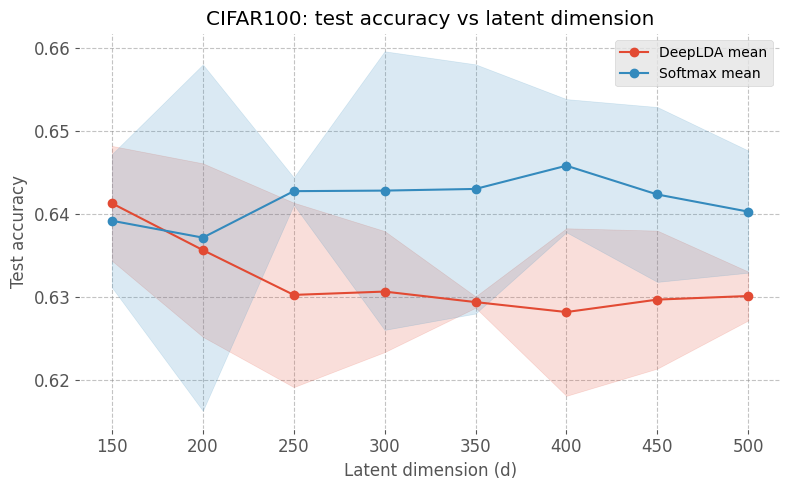

In [4]:
# Plot mean accuracy with solid connecting lines and colored ±2 std bands
plt.figure(figsize=(8, 5))
colors = {"DeepLDA": "C0", "Softmax": "C1"}
alpha_band = 0.18

for model in model_names:
    info = summary_by_model[model]
    dims = info["latent_dims"]
    mean_acc = info["mean"]
    std_2 = [2 * s for s in info["std"]]
    color = colors.get(model)

    lower = [m - s for m, s in zip(mean_acc, std_2)]
    upper = [m + s for m, s in zip(mean_acc, std_2)]
    plt.fill_between(dims, lower, upper, color=color, alpha=alpha_band)
    plt.plot(dims, mean_acc, marker="o", color=color, linewidth=1.5, label=f"{model} mean")

ax = plt.gca()
ax.set_facecolor('none')
plt.gcf().patch.set_alpha(0)
ax.grid(True, color="#888888", alpha=0.5, linestyle='--', linewidth=0.8)

plt.xlabel("Latent dimension (d)")
plt.ylabel("Test accuracy")
plt.title("CIFAR100: test accuracy vs latent dimension")
plt.legend()
plt.tick_params(labelsize=12)
plt.tight_layout()
plt.savefig("cifar100_latent_dim_sweep.png", dpi=600, bbox_inches="tight", transparent=True)
